# Graded alloy blade: creep compliance vs. volume fraction (Sec. 4.5)

Generates `figures/pareto_J_vs_vf_blade.pdf` from `results/5_blade/`. Volume fraction is the fraction of IN625.

- **Homogeneous designs:** uniform IN625 fraction, from `data_evaluation_explicit/homo_design_{i}.pkl`, for fractions 0.0 to 1.0.
- **Graded designs:** one optimized design per target volume fraction, with the final `J` from `data_creep_{int(vf*100)}/history.csv`.

In [1]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "toga" / "__init__.py").is_file())
RUN_DIR = ROOT / "results" / "5_blade"
FIGURES = ROOT / "figures"

In [2]:
# Homogeneous designs
homo_vf, homo_J = [], []
for idx in range(11):
    with open(RUN_DIR / "data_evaluation_explicit" / f"homo_design_{idx}.pkl", "rb") as f:
        data = pickle.load(f)
    homo_vf.append(idx / 10.0)
    homo_J.append(float(data[0]["J"]))
homo_vf, homo_J = np.array(homo_vf), np.array(homo_J)
for vf, J in zip(homo_vf, homo_J):
    print(f"homogeneous  vf={vf:.2f}  J={J:.4g}")

homogeneous  vf=0.00  J=15.29
homogeneous  vf=0.10  J=13.56
homogeneous  vf=0.20  J=12.17
homogeneous  vf=0.30  J=10.99
homogeneous  vf=0.40  J=9.948
homogeneous  vf=0.50  J=9.022
homogeneous  vf=0.60  J=8.188
homogeneous  vf=0.70  J=7.433
homogeneous  vf=0.80  J=6.746
homogeneous  vf=0.90  J=6.121
homogeneous  vf=1.00  J=5.55


In [3]:
# Graded designs
cga_vf, cga_J = [], []
for run_dir in RUN_DIR.glob("data_creep_[0-9]*"):
    history = pd.read_csv(run_dir / "history.csv", sep=r"[,\t]+", engine="python", skipinitialspace=True)
    history.columns = [c.strip() for c in history.columns]
    cga_vf.append(int(run_dir.name.split("_")[-1]) / 100.0)
    cga_J.append(float(history["J"].iloc[-1]))
order = np.argsort(cga_vf)
cga_vf, cga_J = np.array(cga_vf)[order], np.array(cga_J)[order]
for vf, J in zip(cga_vf, cga_J):
    print(f"CGA          vf={vf:.2f}  J={J:.4g}")

CGA          vf=0.10  J=7.198
CGA          vf=0.20  J=5.936
CGA          vf=0.30  J=5.64
CGA          vf=0.40  J=5.566
CGA          vf=0.50  J=5.549
CGA          vf=0.60  J=5.546
CGA          vf=0.70  J=5.546
CGA          vf=0.80  J=5.546
CGA          vf=0.90  J=5.546


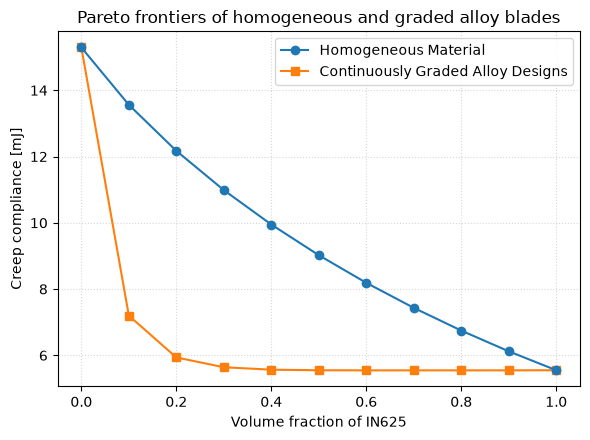

In [4]:
# At vf = 0 and vf = 1 the design is a single material, so both curves share their endpoints.
cga_vf_ext = np.concatenate(([homo_vf[0]], cga_vf, [homo_vf[-1]]))
cga_J_ext = np.concatenate(([homo_J[0]], cga_J, [homo_J[-1]]))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(homo_vf, homo_J, "-o", label="Homogeneous Material", zorder=3)
ax.plot(cga_vf_ext, cga_J_ext, "-s", label="Continuously Graded Alloy Designs", zorder=2)
ax.set_xlabel("Volume fraction of IN625")
ax.set_ylabel("Creep compliance [mJ]")
ax.set_title("Pareto frontiers of homogeneous and graded alloy blades")
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "pareto_J_vs_vf_blade.pdf")
plt.show()

# Smaller version for the README, shown at about half width, so the text is larger.
with plt.rc_context({"font.size": 13}):
    fig, ax = plt.subplots(figsize=(4.4, 3.3))
    ax.plot(homo_vf, homo_J, "-o", ms=5, label="Uniform blend", zorder=3)
    ax.plot(cga_vf_ext, cga_J_ext, "-s", ms=5, label="Graded (optimized)", zorder=2)
    ax.set_xlabel("Volume fraction of IN625")
    ax.set_ylabel("Creep compliance [mJ]")
    ax.grid(True, ls=":", alpha=0.5)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURES / "readme" / "pareto_J_vs_vf_blade.png", dpi=200)
    plt.close(fig)